# Resampling methods

**Name:** Linn Preuss Jelvez

**Date:** 6 october 2026


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

pollution = pd.read_csv('pollution_cleaneddata.csv')
print(pollution.columns)


Index(['PREC', 'JANT', 'JULT', 'OVR65', 'POPN', 'EDUC', 'HOUS', 'DENS', 'NONW',
       'WWDRK', 'POOR', 'HC', 'NOX', 'SO@', 'HUMID', 'MORT'],
      dtype='str')


I use 'pollution_cleaneddata.csv' to predict mortality from the average July temperature with a polynomial regression of degree $p$.

$$ y_i = \beta_0 + \beta_1 x_i + \dots + \beta_p x_i^p + \varepsilon_i $$

Predictive performance is measures by the mean squared error. The polynomial features are fitted on the training data only and then applied to the test data. 

### Validation set approach

the data are split 50/50 into training and test sets and polynomials of degree 1 to 4 are compared. 

   degree    mse_train     mse_test
0       1  2866.993299  4703.889138
1       2  2851.748712  4413.295764
2       3  2828.724250  4286.228553
3       4  2793.821711  4169.294755


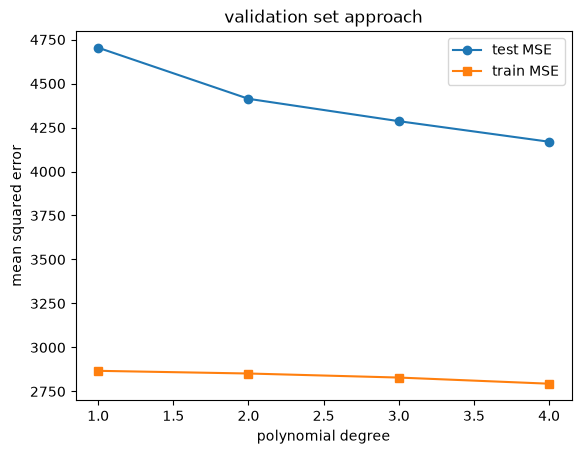

In [2]:
x = pollution[['JULT']].values
y = pollution['MORT'].values

def validation_mse(degree, random_state):
    x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.5, random_state=random_state)

    poly = PolynomialFeatures(degree=degree, include_bias = False)
    x_train_p= poly.fit_transform(x_train)
    x_test_p= poly.transform(x_test)

    model= LinearRegression().fit(x_train_p, y_train)
    y_train_pred = model.predict(x_train_p)
    y_test_pred = model.predict(x_test_p)

    mse_train= mean_squared_error(y_train, y_train_pred)
    mse_test= mean_squared_error(y_test, y_test_pred)
    return mse_train, mse_test

degrees = [1,2,3,4]
rows= []
for d in degrees:
    tr, te = validation_mse(d, random_state=123)
    rows.append({'degree':d, 'mse_train': tr, 'mse_test': te})
results = pd.DataFrame(rows)
print(results)

plt.plot(results['degree'], results['mse_test'], 'o-', label='test MSE')
plt.plot(results['degree'], results['mse_train'], 's-', label='train MSE')
plt.xlabel('polynomial degree')
plt.ylabel('mean squared error')
plt.title('validation set approach')
plt.legend()
plt.show()

    

** Results for seed 123** The training MSE is almost flat for the degrees, as expected. The test MSE is much higher than the training MSE and decreases with degree. Degree 4 gives the smalles MST for new predictions. The improvement from 1 degree to 4 degrees comes from a single random split. 

degree            1            2            3            4
seed                                                      
1       5040.756601  6264.876170  5848.947351  5506.432933
2       3478.233759  6425.207260  5915.792389  5462.582389
3       3667.911949  3508.538872  3462.713780  3412.668122
4       4017.191740  4456.842315  4442.716460  4410.195439
5       2563.018524  2407.977929  2374.796451  2339.727446
6       3747.668835  4266.916605  3992.860150  3751.892741
7       5080.687024  4513.812841  4399.977250  4286.596426
8       2929.449947  3128.792506  3123.821869  3115.643543
9       4716.857745  4532.824707  4483.539444  4429.261480
10      3084.204120  3197.453043  3144.228972  3086.733384


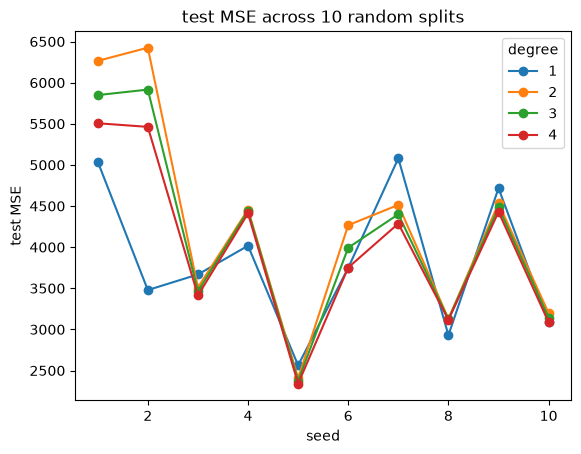

In [3]:
all_rows= []
for seed in range(1,11):
    for d in degrees:
        tr,te = validation_mse(d, random_state=seed)
        all_rows.append({'seed': seed, 'degree':d, 'mse_train':tr, 'mse_test':te})

all_results= pd.DataFrame(all_rows)
pivot_test = all_results.pivot(index='seed', columns='degree', values='mse_test')
print(pivot_test)

pivot_test.plot(marker='o')
plt.xlabel('seed')
plt.ylabel('test MSE')
plt.title('test MSE across 10 random splits')
plt.show()

**Ten other seeds** 
The results are not similar across seeds. 
The best degree changes from seed to seed. Degree 1 has the lowest test MSE in most seeds, degree 4 has the lowest MSE in the rest of the seeds. The test MSE of a single degree varies a lor between seeds. 

The ranking of the models depends on which cities end up in the test set, so one split does not give a confident choice of degree. Beacuse of that I would not choose a high degree based on this evidence. 

### K-Fold cross-validation, degree 2, K=3

The data are split into 3 folds, each fold is held out once and the model is fitted on the other two. The estimate is then the average of the three fold MSEs and this is repeated for seeds 1 to 10.

**Results**: The estimates range from 3513 to 5741 with mean 4407 and SD 879. They are only partly consistent across seeds.

Each test fold contains only 20 cities, which a fold's MSE strongly depends on. The fold MSEs differ a lot even within one seed.

The spread is smaller than for a single 50/50 split. With only K=3 the improvement is ok. 

In [4]:
#K-Fold cross_validation

from sklearn.model_selection import KFold

def kfold_mse(x,y ,degree, K, random_state):
    kf = KFold(n_splits=K, shuffle=True, random_state=random_state)
    scores=[]

    for train_idx, test_idx in kf.split(x):
        xtr, xte = x[train_idx], x[test_idx]
        ytr, yte = y[train_idx], y[test_idx]

        poly = PolynomialFeatures(degree=degree, include_bias = False)
        xtr_p= poly.fit_transform(xtr)
        xte_p = poly.transform(xte)

        model = LinearRegression().fit(xtr_p, ytr)
        y_pred= model.predict(xte_p)
        scores.append(mean_squared_error(yte, y_pred))
    return np.mean(scores)

degree = 2
K=3
cv_estimates = [kfold_mse(x,y,degree, K, random_state=s) for s in range(1,11)]
print('Cv MSE estimates:', cv_estimates)
print('mean:', np.mean(cv_estimates))
print('SD:', np.std(cv_estimates))

Cv MSE estimates: [np.float64(5175.9940782048825), np.float64(5176.310229255291), np.float64(3513.0298772157735), np.float64(3826.803794092671), np.float64(3924.199874134449), np.float64(5740.59770517599), np.float64(3758.7493684999004), np.float64(3576.5170642299986), np.float64(5723.806749641267), np.float64(3658.313779638765)]
mean: 4407.432252008899
SD: 879.4895753563317


## Bootstrap for slope in Poisson regression

I use 'bird_count.csv' and the Poisson regression 
$ Y|x_i \sim Po(\lambda(x_i))$ with $\log \lambda(x_i)= \beta_0 + \beta_1 x_i$,
fitted by maximum likelihood.
**bootstrap procedure**: resample the 13 rows with replacement, refit the model and store the slope. Repeat $B=10.000$ times. The standard error is the standard deviation of the bootstrap slopes. 

In [6]:
# Bootstrap 
import statsmodels.api as sm
import statsmodels.formula.api as smf

birds= pd.read_csv('bird_count.csv')
print(birds.columns.tolist())

['count', 'yr', 'observerAge', 'lineCov']


In [7]:
pois_model = smf.glm('count ~ yr', data=birds, family= sm.families.Poisson()).fit()
print(pois_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  count   No. Observations:                   13
Model:                            GLM   Df Residuals:                       11
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -34.683
Date:                Thu, 08 Oct 2026   Deviance:                       19.128
Time:                        23:09:57   Pearson chi2:                     18.5
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1387
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     67.1792     46.701      1.439      0.1

In [8]:
beta1_hat = pois_model.params['yr']
se_mle = pois_model.bse['yr'] 
print(f'MLE beta1 = {beta1_hat:.5f}')
print(f'MLE SE = {se_mle:.6f}')

MLE beta1 = -0.03244
MLE SE = 0.023290


In [9]:
rng = np.random.default_rng(1)
n = len(birds)
B = 10000
boot_beta = []

for b in range(B):
    idx = rng.integers(0,n ,size=n)
    sample = birds.iloc[idx]
    fit = smf.glm('count ~yr', data=sample, family=sm.families.Poisson()).fit()
    boot_beta.append(fit.params['yr'])

boot_beta = np.array(boot_beta)
print('succesful fits:', len(boot_beta), 'of', B)
print('bootstrap SE:', boot_beta.std(ddof=1))

succesful fits: 10000 of 10000
bootstrap SE: 0.03405431445378128


**Result:** The bootstrap standard error of $\hat\beta_1$ is 0.3405, very close to the reference value 0.0342.

| Method | SE of $\hat\beta_1$ |
|---|---|
| Model-based Poisson (MLE) | 0.0233 |
| Bootstrap ($B = 10\,000$) | 0.0341 |

The bootstrap SE is larger than the model-based SE. The poisson model assumes the variance equals the mean, but the data are overdispersed. 